# SDM-VA-ISAC — Phase 5 : jumeau numérique ISAC double bande

**Projet :** *Semantic Digital Mapping using Vision-Assisted ISAC*
**Phase :** 5 — du nuage de points à un jumeau numérique évalué de la scène
**Scène :** `phase3/new.xml` (quartier gouvernemental de Rabat), mêmes noeuds et mêmes caméras qu'en phases 3-4
**Bandes :** FR1 (3,5 GHz) + FR2 (28 GHz)

### Continuité avec les phases précédentes

| Phase | Acquis réutilisé ici |
|---|---|
| 2 | Chaîne Sionna RT validée (scène, trajets, CIR) |
| 3 | Scène `new.xml`, 4 BS en toiture + 2 capteurs piétons, YOLOv8n fine-tuné, fusion KD-tree, séquence de 6 frames et ses rendus caméra |
| 4 | Grille bayésienne 3D (jumeau numérique de référence), passage à 28 GHz avec seuil de détection |

### Limites des phases 3-4 que cette phase lève

1. **Points radar idéalisés** : chaque point était la position *exacte* d'une interaction calculée par Sionna. Un radar réel ne mesure qu'un retard et un angle d'arrivée ; les trajets à plusieurs rebonds y produisent des fantômes.
2. **Classe radar tirée du matériau** : le radar « savait » qu'un point était une façade ou le sol, ce qui revient à lui donner la vérité terrain. Ici, la classe vient du **Doppler** (cible mobile) ou de la **hauteur** (sol / structure).
3. **Une seule bande** : la phase 4 montre que 28 GHz seul perd l'essentiel des points piétons. On combine ici **FR1** (portée) et **FR2** (résolution, Doppler fin).
4. **Vision limitée au raffinement** : la vision ne pouvait qu'étiqueter un écho radar existant. Ici, elle peut aussi **créer un objet** quand le radar ne voit rien.
5. **Pas d'évaluation** : aucune métrique ne mesurait la qualité de la carte. Le jumeau est ici comparé à la **vérité terrain** de la scène.

### Critères de validation Phase 5
- [ ] Reconstruction radar exacte en l'absence de bruit (retard + angle d'arrivée)
- [ ] FR2 plus précis que FR1 ; cibles mobiles séparables par Doppler en FR2
- [ ] La fusion FR1 + FR2 améliore la couverture des structures par rapport à chaque bande seule
- [ ] Les objets créés par la vision améliorent la détection des piétons
- [ ] Faux objets mobiles rares dans la configuration finale (moins de 0,5 par frame en moyenne)
- [ ] `phase5_summary.json` produit

## 0. Configuration

In [1]:
from __future__ import annotations

import json
import sys
import time
import types
from collections import Counter
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import mitsuba as mi
from scipy.ndimage import binary_dilation
from scipy.spatial import cKDTree
from IPython.display import HTML, display

try:
    mi.set_variant("cuda_ad_mono_polarized")
    print(f"Variante GPU activee : {mi.variant()}")
except Exception as e:
    print(f"CUDA indisponible ({e}), repli sur LLVM CPU")
    mi.set_variant("llvm_ad_mono_polarized")

from sionna.rt import load_scene, Transmitter, Receiver, PlanarArray, PathSolver, RadioMaterial

WORKSPACE = Path(r"C:\Users\AdminFix\Desktop\PFA")
PHASE3_DIR = WORKSPACE / "phase3"
PHASE5_DIR = WORKSPACE / "phase5"
PHASE5_DIR.mkdir(exist_ok=True)
SCENE_XML = PHASE3_DIR / "new.xml"

C0 = 299_792_458.0
MAX_DEPTH = 4
IMG_W, IMG_H = 1280, 960
N_FRAMES = 6
FRAME_PERIOD_S = 0.5            # 1,5 m/frame -> 3 m/s (voiture) ; 0,8 m/frame -> 1,6 m/s (pietons)
FRAME_SPEED = {"car": 1.5, "pedestrian_a": 0.8, "pedestrian_b": 0.8}   # m/frame, comme en phase 3
CPI_S = 10e-3                   # duree d'integration coherente radar
SNR_MIN_DB = 13.0               # Pd ~0,9 pour Pfa ~1e-6
rng = np.random.default_rng(7)
plt.rcParams.update({"font.size": 15, "axes.spines.top": False, "axes.spines.right": False})


def table(cols):
    """Tableau HTML {colonne: {ligne: valeur}} (pandas n'est pas compatible avec numpy 2 ici)."""
    names = list(cols)
    rows = list(next(iter(cols.values())))
    head = "".join(f"<th>{n}</th>" for n in names)
    body = "".join("<tr><th style='text-align:left'>" + r + "</th>"
                   + "".join(f"<td>{cols[n][r]}</td>" for n in names) + "</tr>" for r in rows)
    return HTML(f"<table><tr><th></th>{head}</tr>{body}</table>")


assert SCENE_XML.exists(), f"Fichier introuvable : {SCENE_XML}"
print(f"Scene : {SCENE_XML}")

jitc_llvm_init(): LLVM API initialization failed ..


Variante GPU activee : cuda_ad_mono_polarized


Scene : C:\Users\AdminFix\Desktop\PFA\phase3\new.xml


## 1. Les deux bandes et leur bilan de liaison

Chaque bande a son propre bilan de liaison ; un trajet est détecté si
$P_{tx} + G_{trajet} + G_{réseaux} + G_{traitement} - N \geq 13$ dB, comme en phase 4.

- **FR1 (3,5 GHz)** : macro en toiture, 100 MHz, réseau 8×8, 43 dBm — portée et robustesse.
- **FR2 (28 GHz)** : mmWave, 400 MHz, réseau 16×16, 30 dBm — résolution en distance, en angle et en Doppler.

Par rapport à la phase 4 : le gain de réseau compte l'émission **et** la réception (radar
monostatique), et le signal de référence de sensing (1/4 des sous-porteuses, 2 symboles par slot)
est intégré sur un CPI de 10 ms, ce qui fixe aussi la résolution Doppler (100 Hz).

In [2]:
def make_band(freq, bw, scs, n_array, tx_dbm, nf_db):
    n_sc = int(bw / scs * 0.95) // 4                  # ~95 % de bande utile, peigne 1/4
    slots = int(CPI_S / (1e-3 / (scs / 15e3)))       # un slot dure 1 ms / (scs / 15 kHz)
    n_sym = 2 * slots
    g_proc = 10 * np.log10(n_sc * n_sym)
    g_array = 2 * 10 * np.log10(n_array ** 2)         # reseau d'emission + reseau de reception
    noise = -174.0 + 10 * np.log10(bw) + nf_db
    return {"freq_hz": freq, "bw_hz": bw, "n_array": n_array, "tx_dbm": tx_dbm, "nf_db": nf_db,
            "g_proc_db": g_proc, "g_array_db": g_array, "noise_dbm": noise,
            "path_gain_min_db": SNR_MIN_DB + noise - tx_dbm - g_array - g_proc,
            "range_res_m": C0 / (2 * bw), "beamwidth_rad": 1.772 / n_array,
            "doppler_res_hz": 1.0 / CPI_S}


BANDS = {"FR1": make_band(3.5e9, 100e6, 30e3, 8, 43.0, 5.0),
         "FR2": make_band(28e9, 400e6, 120e3, 16, 30.0, 7.0)}
# Peau humaine (modele de Gabriel 1996, peau seche) : permittivite relative, conductivite [S/m]
SKIN = {"FR1": (37.0, 2.0), "FR2": (16.6, 25.8)}

table({b: {"Frequence (GHz)": p["freq_hz"] / 1e9, "Bande (MHz)": p["bw_hz"] / 1e6,
           "Reseau": f'{p["n_array"]}x{p["n_array"]}', "P_tx (dBm)": p["tx_dbm"],
           "Bruit (dBm)": f'{p["noise_dbm"]:.1f}', "G reseaux (dB)": f'{p["g_array_db"]:.1f}',
           "G traitement (dB)": f'{p["g_proc_db"]:.1f}',
           "Gain de trajet minimal (dB)": f'{p["path_gain_min_db"]:.1f}',
           "Resolution en distance (m)": f'{p["range_res_m"]:.3f}',
           "Ouverture a -3 dB (deg)": f'{np.degrees(p["beamwidth_rad"]):.1f}',
           "Resolution Doppler (Hz)": p["doppler_res_hz"]}
       for b, p in BANDS.items()})

,FR1,FR2
Frequence (GHz),3.5,28.0
Bande (MHz),100.0,400.0
Reseau,8x8,16x16
P_tx (dBm),43.0,30.0
Bruit (dBm),-89.0,-81.0
G reseaux (dB),36.1,48.2
G traitement (dB),45.0,51.0
Gain de trajet minimal (dB),-200.1,-197.2
Resolution en distance (m),1.499,0.375
Ouverture a -3 dB (deg),12.7,6.3


## 2. Scène, acteurs et noeuds (reprise de la phase 3)

Mêmes acteurs, mêmes coefficients de diffusion et mêmes noeuds qu'en phase 3, avec deux ajouts :
- les acteurs reçoivent une **vitesse réelle**, pour que Sionna calcule le Doppler de chaque trajet ;
- les piétons passent du bois ITU à un matériau **« peau »** dépendant de la bande (la couleur de
  rendu est conservée, donc les images caméra de la phase 3 restent valables).

Seules les 4 BS portent un **réseau** d'antennes et peuvent donc mesurer un angle d'arrivée. Les
deux capteurs piétons (récepteur à une antenne + caméra) servent à la vision ; leur récepteur,
sans angle d'arrivée, ne permet pas de localiser un écho et n'est pas utilisé pour le radar.

In [3]:
t0 = time.time()
scene = load_scene(str(SCENE_XML), merge_shapes=False, remove_duplicate_vertices=False)
print(f"Scene chargee en {time.time()-t0:.2f} s ({len(scene.objects)} objets)")

ACTOR_MATERIALS = {"car": {"itu_metal", "itu_glass", "itu_car_wood"},
                   "pedestrian_a": {"itu_ped_a_wood"}, "pedestrian_b": {"itu_ped_B_wood"}}
STATIC_CLASS = {"itu_brick": "structure", "itu_ceiling_board": "structure",
                "itu_concrete": "ground", "itu_very_dry_ground": "ground"}

group_objects = {g: [] for g in ACTOR_MATERIALS}
objid_group, objid_class = {}, {}
for name, obj in scene.objects.items():
    mat, oid = obj.radio_material.name, int(obj.object_id)
    for g, mats in ACTOR_MATERIALS.items():
        if mat in mats:
            group_objects[g].append(obj)
            objid_group[oid] = g
    objid_class[oid] = STATIC_CLASS.get(mat, "actor")

# Coefficients de diffusion de la phase 3
for m in ("itu_metal", "itu_glass", "itu_car_wood", "itu_ped_a_wood", "itu_ped_B_wood"):
    scene.radio_materials[m].scattering_coefficient = 0.4
for m in ("itu_brick", "itu_ceiling_board"):
    scene.radio_materials[m].scattering_coefficient = 0.05

# Materiau "peau" par bande, meme couleur de rendu que le materiau d'origine
ped_colors = {g: tuple(float(c) for c in group_objects[g][0].radio_material.color)
              for g in ("pedestrian_a", "pedestrian_b")}
skin_mats = {(g, b): RadioMaterial(name=f"skin_{g}_{b}", relative_permittivity=SKIN[b][0],
                                   conductivity=SKIN[b][1], scattering_coefficient=0.4,
                                   color=ped_colors[g])
             for g in ped_colors for b in BANDS}


def group_centroid(objs):
    lo = np.array([np.array(o.mi_mesh.bbox().min).flatten() for o in objs]).min(axis=0)
    hi = np.array([np.array(o.mi_mesh.bbox().max).flatten() for o in objs]).max(axis=0)
    return (lo + hi) / 2


c0 = {g: group_centroid(objs) for g, objs in group_objects.items()}
actors_c0 = np.mean(list(c0.values()), axis=0)
heading = {g: np.array([*((actors_c0 - c0[g])[:2] / np.linalg.norm((actors_c0 - c0[g])[:2])), 0.0])
           for g in ACTOR_MATERIALS}
init_pos = {g: [np.array(o.position).flatten() for o in group_objects[g]] for g in ACTOR_MATERIALS}


def set_frame(t):
    """Place les acteurs a la frame t et leur donne leur vitesse (pour le Doppler)."""
    for g in ACTOR_MATERIALS:
        vel = heading[g] * FRAME_SPEED[g] / FRAME_PERIOD_S
        for obj, p0 in zip(group_objects[g], init_pos[g]):
            obj.position = mi.Point3f(*(p0 + heading[g] * FRAME_SPEED[g] * t).tolist())
            obj.velocity = mi.Vector3f(*vel.tolist())
    return {g: c0[g] + heading[g] * FRAME_SPEED[g] * t for g in ACTOR_MATERIALS}


for g, c in c0.items():
    print(f"  acteur '{g}': centroide {c.round(2)}, vitesse {FRAME_SPEED[g] / FRAME_PERIOD_S:.1f} m/s")

Scene chargee en 0.31 s (74 objets)
  acteur 'car': centroide [-34.07  92.75   1.65], vitesse 3.0 m/s
  acteur 'pedestrian_a': centroide [-46.36  60.76   0.9 ], vitesse 1.6 m/s
  acteur 'pedestrian_b': centroide [-51.8  106.96   0.9 ], vitesse 1.6 m/s


In [4]:
# -- 4 BS en toiture (bi-bande FR1 + FR2), positions de la phase 3 --
BS_POS = {"TX1": np.array([-119.55, 54.933, 20.79 + 1.5]),
          "TX2": np.array([47.9, 110.0, 18.0 + 1.5]),
          "TX3": np.array([43.7, 33.0, 21.8 + 1.5]),
          "TX4": np.array([107.0, -28.6, 19.7 + 1.5])}
RX_OFFSET = np.array([0.3, 0.3, -0.2])          # reseau de reception co-localise (monostatique)
# -- 2 capteurs pietons (camera ; recepteur a une antenne), positions de la phase 3 --
PED_NODE_POS = {"ped_a": c0["pedestrian_a"] + np.array([-6.0, -7.0, 3.5]),
                "ped_b": c0["pedestrian_b"] + np.array([-6.0, 7.0, 3.5])}

BS_NAMES = list(BS_POS)
for n in BS_NAMES:
    scene.add(Transmitter(name=f"tx_{n}", position=BS_POS[n].tolist()))
    scene.add(Receiver(name=f"rx_{n}", position=(BS_POS[n] + RX_OFFSET).tolist()))
assert [k[3:] for k in scene.receivers] == BS_NAMES
TX_POS = np.array([BS_POS[n] for n in BS_NAMES])
RX_POS = TX_POS + RX_OFFSET
for n, p in {**BS_POS, **PED_NODE_POS}.items():
    print(f"  {n:6s} @ {np.round(p, 2)}")

  TX1    @ [-119.55   54.93   22.29]
  TX2    @ [ 47.9 110.   19.5]
  TX3    @ [43.7 33.  23.3]
  TX4    @ [107.  -28.6  21.2]
  ped_a  @ [-52.36  53.76   4.4 ]
  ped_b  @ [-57.8  113.96   4.4 ]


## 3. Module 1a — mesures ISAC double bande

Pour chaque trajet reçu par le réseau d'une BS, le radar mesure :
- un **retard**, donc la longueur totale $L$ du trajet ;
- un **angle d'arrivée** $\hat{u}$ ;
- un **décalage Doppler**.

Le point reconstruit est sur la direction d'arrivée, à la distance compatible avec $L$
(ellipse bistatique, $L/2$ en monostatique) :
$$\mathbf{p} = \mathbf{r} + t\,\hat{u},\qquad t = \frac{L^2 - \|\mathbf{d}\|^2}{2\,(L - \hat{u}\cdot\mathbf{d})},\qquad \mathbf{d} = \mathbf{e} - \mathbf{r}$$
où $\mathbf{r}$ et $\mathbf{e}$ sont les positions du récepteur et de l'émetteur. Un bruit est
ajouté en distance ($\sigma_r = \Delta r / \sqrt{2\,\mathrm{SNR}}$) et en angle
($\sigma_\theta = \theta_{3dB} / \sqrt{2\,\mathrm{SNR}}$), avec un plancher à 1/10 de la résolution.

Pour un écho à un seul rebond, le point est la vraie réflexion. Pour un écho à plusieurs rebonds,
c'est un **fantôme**, exactement comme sur un radar réel.

In [5]:
solver = PathSolver()
INVALID = np.uint32(0xFFFFFFFF)
ACTOR_IDS = np.array(list(objid_group), dtype=np.uint32)
AOA_SIGN = None


def isac_measurements(band_name, frame):
    """Trace de rayons dans une bande, puis conversion des trajets en mesures radar apparentes."""
    global AOA_SIGN
    band = BANDS[band_name]
    scene.frequency, scene.bandwidth = band["freq_hz"], band["bw_hz"]
    # Elements isotropes : couverture supposee assuree par secteurs, gain de reseau porte au bilan
    scene.tx_array = PlanarArray(num_rows=1, num_cols=1, pattern="iso", polarization="V")
    scene.rx_array = PlanarArray(num_rows=1, num_cols=1, pattern="iso", polarization="V")
    for g in ped_colors:
        for obj in group_objects[g]:
            obj.radio_material = skin_mats[(g, band_name)]

    paths = solver(scene, max_depth=MAX_DEPTH, los=True, specular_reflection=True,
                   diffuse_reflection=True, refraction=False, diffraction=True,
                   edge_diffraction=False, seed=42 + frame)
    valid = np.array(paths.valid).astype(bool)
    tau, doppler = np.array(paths.tau), np.array(paths.doppler)
    theta_r, phi_r = np.array(paths.theta_r), np.array(paths.phi_r)
    objs, verts = np.array(paths.objects), np.array(paths.vertices)
    a, _ = paths.cir(sampling_frequency=band["bw_hz"], num_time_steps=1,
                     normalize_delays=False, out_type="numpy")
    gain_db = 10 * np.log10(np.abs(a[:, 0, :, 0, :, 0]) ** 2 + 1e-30)

    # trajets avec au moins une interaction (le trajet direct n'est pas un echo)
    r_i, t_i, p_i = np.nonzero(valid & (objs[0] != INVALID))
    # ordre stable (recepteur, emetteur, retard) : le GPU ne renvoie pas toujours les trajets dans
    # le meme ordre, et le bruit doit etre attribue aux memes trajets d'une execution a l'autre
    order = np.lexsort((tau[r_i, t_i, p_i], t_i, r_i))
    r_i, t_i, p_i = r_i[order], t_i[order], p_i[order]
    depth = (objs[:, r_i, t_i, p_i] != INVALID).sum(axis=0)
    last_vertex = verts[depth - 1, r_i, t_i, p_i]
    u = np.stack([np.sin(theta_r) * np.cos(phi_r), np.sin(theta_r) * np.sin(phi_r),
                  np.cos(theta_r)], -1)[r_i, t_i, p_i]
    rxp, txp = RX_POS[r_i], TX_POS[t_i]
    if AOA_SIGN is None:       # convention : l'angle d'arrivee pointe-t-il vers la reflexion ?
        one = depth == 1
        to_v = last_vertex[one] - rxp[one]
        to_v /= np.linalg.norm(to_v, axis=1, keepdims=True)
        AOA_SIGN = float(np.sign(np.median((to_v * u[one]).sum(1))))
    u = AOA_SIGN * u

    L = C0 * tau[r_i, t_i, p_i]
    d = txp - rxp
    dist = (L ** 2 - (d ** 2).sum(1)) / (2 * (L - (u * d).sum(1)))
    snr = (band["tx_dbm"] + gain_db[r_i, t_i, p_i] + band["g_array_db"] + band["g_proc_db"]
           - band["noise_dbm"])
    snr_lin = 10 ** (snr / 10)
    sig_r = np.maximum(band["range_res_m"] / 10, band["range_res_m"] / np.sqrt(2 * snr_lin))
    sig_a = np.maximum(band["beamwidth_rad"] / 10, band["beamwidth_rad"] / np.sqrt(2 * snr_lin))
    return {"tx": t_i, "rx": r_i, "depth": depth, "snr_db": snr,
            "doppler_hz": doppler[r_i, t_i, p_i],
            "u": u, "dist": dist, "rxp": rxp, "sig_r": sig_r, "sig_a": sig_a,
            "point_clean": rxp + dist[:, None] * u,
            "last_vertex": last_vertex,
            "mover_gt": np.isin(objs[:, r_i, t_i, p_i], ACTOR_IDS).any(axis=0)}


def noisy_points(m, gen):
    """Un tirage du bruit de mesure : distance + deux composantes angulaires orthogonales."""
    u = m["u"]
    e1 = np.cross(u, [0.0, 0.0, 1.0])
    e1 /= np.linalg.norm(e1, axis=1, keepdims=True) + 1e-12
    e2 = np.cross(u, e1)
    n = gen.standard_normal((len(u), 3))
    u_n = u + (m["sig_a"] * n[:, 1])[:, None] * e1 + (m["sig_a"] * n[:, 2])[:, None] * e2
    u_n /= np.linalg.norm(u_n, axis=1, keepdims=True)
    return m["rxp"] + (m["dist"] + m["sig_r"] * n[:, 0])[:, None] * u_n

## 4. Module 1b — vision (reprise de la phase 3)

Mêmes caméras et même détecteur YOLOv8n fine-tuné qu'en phase 3. Les poses et la géométrie étant
identiques, on réutilise directement les rendus de la phase 3 (`module1b_camera_*.png` pour la
frame 0, `frames_v2/` pour les frames 1 à 5).

In [6]:
if "mlflow" not in sys.modules:
    sys.modules["mlflow"] = types.ModuleType("mlflow")
from ultralytics import YOLO

yolo_model = YOLO(str(PHASE3_DIR / "yolo_finetune_v2" / "weights" / "best.pt"))


def look_at_rotation(cam_pos, target, up=np.array([0.0, 0.0, 1.0])):
    forward = np.asarray(target, float) - np.asarray(cam_pos, float)
    forward /= np.linalg.norm(forward) + 1e-12
    right = np.cross(forward, up)
    right /= np.linalg.norm(right) + 1e-12
    return np.stack([right, np.cross(right, forward), -forward], axis=0)


def project_point(p_world, cam_pos, R_wc, f_px):
    p_cam = R_wc @ (np.asarray(p_world) - cam_pos)
    if p_cam[2] >= 0:
        return None
    u = f_px * (p_cam[0] / -p_cam[2]) + IMG_W / 2
    v = -f_px * (p_cam[1] / -p_cam[2]) + IMG_H / 2
    return (float(u), float(v)) if (0 <= u < IMG_W and 0 <= v < IMG_H) else None


def vision_frame(t, cur):
    """Detections YOLO des 6 cameras a la frame t, avec la geometrie de chaque camera."""
    look = np.mean(list(cur.values()), axis=0)
    poses = {"tx1": (BS_POS["TX1"], look, 25.0), "tx2": (BS_POS["TX2"], look, 25.0),
             "tx3": (BS_POS["TX3"], look, 25.0), "tx4": (BS_POS["TX4"], look, 25.0),
             "ped_a": (PED_NODE_POS["ped_a"], cur["pedestrian_a"], 45.0),
             "ped_b": (PED_NODE_POS["ped_b"], cur["pedestrian_b"], 45.0)}
    cams = {}
    for cam, (pos, target, fov) in poses.items():
        img = (PHASE3_DIR / f"module1b_camera_{cam}.png" if t == 0
               else PHASE3_DIR / "frames_v2" / f"frame_{t:02d}_{cam}.png")
        res = yolo_model.predict(source=str(img), verbose=False)[0]
        dets = []
        if res.boxes is not None:
            for box, cls_id, conf in zip(res.boxes.xyxy.cpu().numpy(), res.boxes.cls.cpu().numpy(),
                                         res.boxes.conf.cpu().numpy()):
                dets.append({"bbox_xyxy": box.tolist(), "cls": yolo_model.names[int(cls_id)],
                             "conf": float(conf)})
        cams[cam] = {"pos": np.asarray(pos), "R": look_at_rotation(pos, target),
                     "f_px": (IMG_W / 2) / np.tan(np.radians(fov) / 2), "detections": dets}
    return cams

### Simulation des 6 frames (radar double bande + vision)

In [7]:
MEAS, FRAMES = {}, []
t0 = time.time()
for t in range(N_FRAMES):
    cur = set_frame(t)
    for b in BANDS:
        MEAS[(b, t)] = isac_measurements(b, t)
    FRAMES.append({"actors": cur, "cameras": vision_frame(t, cur)})
    n_det = {b: int((MEAS[(b, t)]["snr_db"] >= SNR_MIN_DB).sum()) for b in BANDS}
    dets = {k: [d["cls"] for d in v["detections"]] for k, v in FRAMES[-1]["cameras"].items()}
    print(f"frame {t}: echos detectes {n_det} | vision {dets}")
print(f"\nConvention d'angle d'arrivee : signe {AOA_SIGN:+.0f} | simulation terminee en {time.time()-t0:.0f} s")

frame 0: echos detectes {'FR1': 9339, 'FR2': 7138} | vision {'tx1': ['car'], 'tx2': ['car'], 'tx3': ['car'], 'tx4': [], 'ped_a': ['pedestrian', 'car'], 'ped_b': ['pedestrian', 'car']}


frame 1: echos detectes {'FR1': 9670, 'FR2': 7413} | vision {'tx1': ['car'], 'tx2': ['car', 'pedestrian'], 'tx3': ['car'], 'tx4': [], 'ped_a': ['pedestrian', 'car'], 'ped_b': ['pedestrian', 'car']}


frame 2: echos detectes {'FR1': 9854, 'FR2': 7584} | vision {'tx1': ['car'], 'tx2': ['car', 'pedestrian', 'pedestrian'], 'tx3': ['car'], 'tx4': [], 'ped_a': ['pedestrian', 'car'], 'ped_b': ['pedestrian', 'car']}


frame 3: echos detectes {'FR1': 9291, 'FR2': 7172} | vision {'tx1': ['car'], 'tx2': ['car', 'pedestrian', 'pedestrian', 'pedestrian'], 'tx3': ['car', 'pedestrian'], 'tx4': [], 'ped_a': ['pedestrian', 'car'], 'ped_b': ['pedestrian', 'car']}


frame 4: echos detectes {'FR1': 9456, 'FR2': 7286} | vision {'tx1': ['car', 'pedestrian', 'pedestrian'], 'tx2': ['car', 'pedestrian', 'pedestrian'], 'tx3': ['car', 'pedestrian'], 'tx4': [], 'ped_a': ['pedestrian', 'car'], 'ped_b': ['pedestrian', 'car']}


frame 5: echos detectes {'FR1': 9501, 'FR2': 7336} | vision {'tx1': ['car', 'pedestrian', 'pedestrian'], 'tx2': ['car', 'pedestrian', 'pedestrian'], 'tx3': ['car', 'pedestrian', 'pedestrian'], 'tx4': [], 'ped_a': ['pedestrian', 'car'], 'ped_b': ['car', 'pedestrian']}

Convention d'angle d'arrivee : signe +1 | simulation terminee en 31 s


### Tirages du bruit de mesure

La géométrie des trajets est calculée une seule fois ; le bruit de mesure est ensuite tiré
**10 fois** de façon indépendante. Toutes les métriques du jumeau sont données en
**moyenne ± écart-type sur ces 10 tirages**, ce qui évite de tirer des conclusions d'une réalisation
particulière du bruit. Les figures et les tableaux détaillés utilisent le premier tirage, dit
*de référence*.

In [8]:
N_TRIALS = 10
TRIAL_POINTS = [{k: noisy_points(m, np.random.default_rng(1000 + i)) for k, m in MEAS.items()}
                for i in range(N_TRIALS)]
for k, m in MEAS.items():
    m["point"] = TRIAL_POINTS[0][k]          # tirage de reference
print(f"{N_TRIALS} tirages independants du bruit de mesure prepares")

10 tirages independants du bruit de mesure prepares


### Vérification de la physique des mesures

- Sans bruit, un écho à un rebond doit retomber exactement sur la réflexion : cela valide la
  reconstruction par retard + angle d'arrivée.
- Avec bruit, FR2 doit être plus précis que FR1 (bande 4 fois plus large, réseau 2 fois plus grand).
- Les échos sur les acteurs doivent dépasser la résolution Doppler (100 Hz) en FR2 : un piéton à
  1,6 m/s donne jusqu'à $2v/\lambda \approx 300$ Hz à 28 GHz, mais seulement $\approx 37$ Hz à 3,5 GHz.

,FR1,FR2
Echos detectes,9339,7138
"Erreur sans bruit, 1 rebond (m)",0.010,0.008
"Erreur avec bruit, 1 rebond (m)",2.01,0.42
Part d'echos a plusieurs rebonds,27%,31%
|Doppler| median sur les acteurs (Hz),45,357
Echos d'acteurs separables (>= 100 Hz),0%,96%


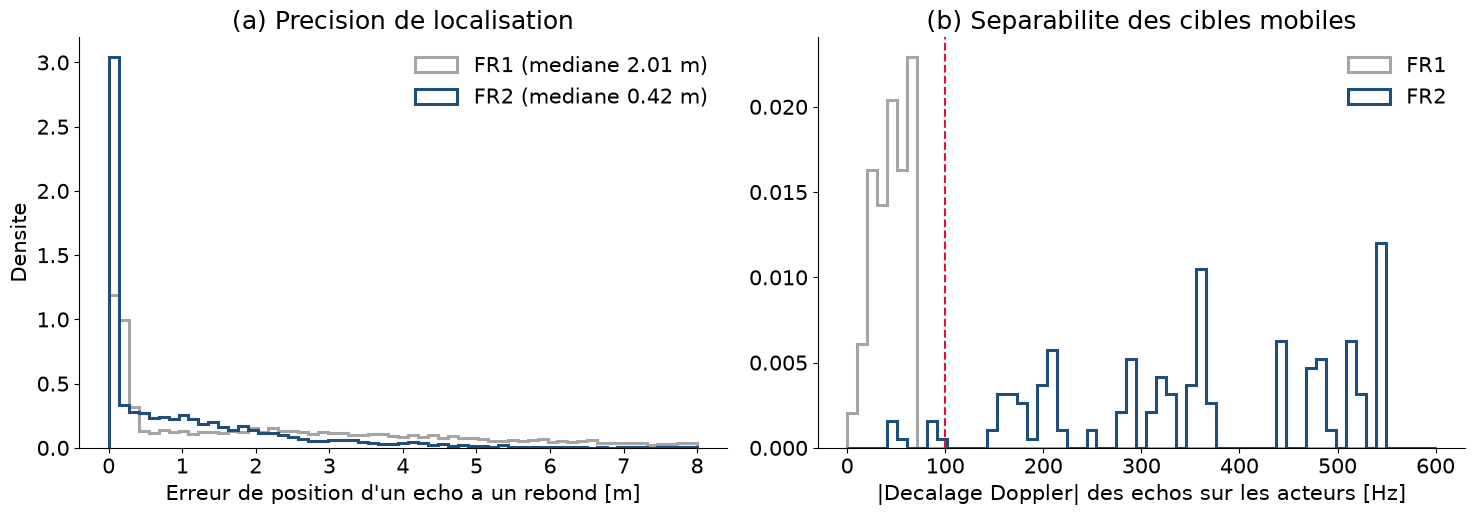

In [9]:
check = {}
for b in BANDS:
    m = MEAS[(b, 0)]
    det = m["snr_db"] >= SNR_MIN_DB
    one = det & (m["depth"] == 1)
    fd = np.abs(m["doppler_hz"][det & m["mover_gt"]])
    check[b] = {
        "Echos detectes": int(det.sum()),
        "Erreur sans bruit, 1 rebond (m)": f'{np.median(np.linalg.norm(m["point_clean"][one] - m["last_vertex"][one], axis=1)):.3f}',
        "Erreur avec bruit, 1 rebond (m)": f'{np.median(np.linalg.norm(m["point"][one] - m["last_vertex"][one], axis=1)):.2f}',
        "Part d'echos a plusieurs rebonds": f'{(det & (m["depth"] > 1)).sum() / det.sum():.0%}',
        "|Doppler| median sur les acteurs (Hz)": f"{np.median(fd):.0f}",
        "Echos d'acteurs separables (>= 100 Hz)": f"{(fd >= 100).mean():.0%}",
    }
display(table(check))

fig, axes = plt.subplots(1, 2, figsize=(15, 5.4))
for b, col in [("FR1", "#a5a5a5"), ("FR2", "#1f4e79")]:
    m = MEAS[(b, 0)]
    det = m["snr_db"] >= SNR_MIN_DB
    one = det & (m["depth"] == 1)
    err = np.linalg.norm(m["point"][one] - m["last_vertex"][one], axis=1)
    axes[0].hist(err, bins=np.linspace(0, 8, 60), histtype="step", lw=2.2, color=col, density=True,
                 label=f"{b} (mediane {np.median(err):.2f} m)")
    axes[1].hist(np.abs(m["doppler_hz"][det & m["mover_gt"]]), bins=np.linspace(0, 600, 60),
                 histtype="step", lw=2.2, color=col, density=True, label=b)
axes[0].set(xlabel="Erreur de position d'un echo a un rebond [m]", ylabel="Densite",
            title="(a) Precision de localisation")
axes[1].axvline(100, color="crimson", ls="--")
axes[1].set(xlabel="|Decalage Doppler| des echos sur les acteurs [Hz]",
            title="(b) Separabilite des cibles mobiles")
for ax in axes:
    ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(PHASE5_DIR / "module1a_mesures_fr1_fr2.png", dpi=180, bbox_inches="tight")
plt.show()

## 5. Vérité terrain de la scène

Pour évaluer le jumeau, on échantillonne la géométrie réelle dans la zone des bâtiments
(environ 375 × 350 m) :
- **structures** : points tirés uniformément sur les murs et les toits (1 point par 0,25 m²) ;
- **sol visible** : lancer vertical sur une grille de 1 m ; on garde les points où la première
  surface rencontrée est à moins de 0,5 m (sol ou route).

In [10]:
ROI_MIN = np.array([-176.0, -186.0, 0.0])
ROI_MAX = np.array([202.0, 170.0, 26.0])
VOXEL = 2.0

set_frame(0)
gt_struct = []
for name, obj in scene.objects.items():
    if objid_class.get(int(obj.object_id)) != "structure":
        continue
    params = mi.traverse(obj.mi_mesh)
    V = np.array(params["vertex_positions"]).reshape(-1, 3)
    F = np.array(params["faces"]).reshape(-1, 3)
    A, B, Cv = V[F[:, 0]], V[F[:, 1]], V[F[:, 2]]
    area = 0.5 * np.linalg.norm(np.cross(B - A, Cv - A), axis=1)
    tri = np.repeat(np.arange(len(F)), np.maximum(1, np.ceil(area / 0.25).astype(int)))
    s1, r2 = np.sqrt(rng.random(len(tri))), rng.random(len(tri))
    gt_struct.append((1 - s1)[:, None] * A[tri] + (s1 * (1 - r2))[:, None] * B[tri]
                     + (s1 * r2)[:, None] * Cv[tri])
GT_STRUCT = np.concatenate(gt_struct)
GT_STRUCT = GT_STRUCT[np.all((GT_STRUCT >= ROI_MIN) & (GT_STRUCT <= ROI_MAX), axis=1)]

gx, gy = np.meshgrid(np.arange(ROI_MIN[0], ROI_MAX[0], 1.0) + 0.5, np.arange(ROI_MIN[1], ROI_MAX[1], 1.0) + 0.5)
gx, gy = gx.ravel().astype(np.float32), gy.ravel().astype(np.float32)
si = scene.mi_scene.ray_intersect(mi.Ray3f(o=mi.Point3f(mi.Float(gx), mi.Float(gy), mi.Float(np.full(gx.size, 200.0, np.float32))),
                                           d=mi.Vector3f(0.0, 0.0, -1.0)))
hit_z, hit = np.array(si.p.z), np.array(si.is_valid()).astype(bool)
GT_GROUND = np.c_[gx, gy, hit_z][hit & (hit_z < 0.5)]
print(f"Verite terrain : {len(GT_STRUCT)} points de structure, {len(GT_GROUND)} points de sol visible")

Verite terrain : 309410 points de structure, 118391 points de sol visible


## 6. Module 2 — fusion radar-vision

- **Raffinement** (comme en phase 3) : chaque écho mobile est projeté dans les caméras ; dans
  chaque caméra, on cherche la détection au centroïde le plus proche, acceptée sous un rayon égal
  à la demi-diagonale de sa boîte. **Correction par rapport à la phase 3** : entre caméras, on
  retient la plus petite distance *relative* (distance / demi-diagonale) et non la plus petite
  distance en pixels. En pixels, les caméras lointaines, où tout paraît petit, l'emportaient à
  tort : à la frame 0, les caméras en toiture ne voient que la voiture, et les échos du piéton B,
  projetés près de cette voiture, étaient étiquetés « car ».
- **Contrôle de profondeur** (nouveau) : une image ne dit pas si un écho est devant ou derrière
  l'objet détecté. On estime la distance caméra–objet en projetant au sol le bas de sa boîte, et
  on refuse l'association si elle diffère de la distance caméra–écho de plus de max(4 m, 10 %).
  C'est la réponse directe à la confusion de profondeur identifiée en phase 3.
- **Objets créés par la vision** (nouveau) : une détection qu'aucun écho radar n'a confirmée
  devient un objet, placé au sol par projection du bas-centre de la boîte (pose de caméra connue).
  C'est ce qui permet à la vision de compenser un radar qui ne voit pas une cible.

In [11]:
DEPTH_TOL_M, DEPTH_TOL_REL = 4.0, 0.10       # tolerance du controle de profondeur


def backproject_to_ground(u, v, cam_pos, R_wc, f_px, z_ground=0.0):
    d_world = R_wc.T @ np.array([(u - IMG_W / 2) / f_px, -(v - IMG_H / 2) / f_px, -1.0])
    if d_world[2] >= -1e-6:
        return None
    return cam_pos + (z_ground - cam_pos[2]) / d_world[2] * d_world


def refine(p, cams):
    """KD-tree sur les centroides des boites de chaque camera, rayon d'acceptation = demi-diagonale.
    Le meilleur noeud est celui de plus petite distance *relative* (distance / demi-diagonale) :
    une distance en pixels favoriserait les cameras lointaines, ou tout parait petit."""
    best, best_d, best_key = None, np.inf, None
    for cam, c in cams.items():
        if not c["detections"]:
            continue
        uv = project_point(p, c["pos"], c["R"], c["f_px"])
        if uv is None:
            continue
        cent = np.array([[(d["bbox_xyxy"][0] + d["bbox_xyxy"][2]) / 2,
                          (d["bbox_xyxy"][1] + d["bbox_xyxy"][3]) / 2] for d in c["detections"]])
        dist, j = cKDTree(cent).query(uv)
        x0, y0, x1, y1 = c["detections"][j]["bbox_xyxy"]
        rel = dist / (0.5 * np.hypot(x1 - x0, y1 - y0))
        if rel > 1.0 or rel >= best_d:
            continue
        # controle de profondeur : distance camera -> echo radar comparee a la distance
        # camera -> objet (bas de la boite projete au sol)
        g = backproject_to_ground((x0 + x1) / 2, y1, c["pos"], c["R"], c["f_px"])
        if g is not None:
            r_det, r_echo = np.linalg.norm(g - c["pos"]), np.linalg.norm(np.asarray(p) - c["pos"])
            if abs(r_echo - r_det) > max(DEPTH_TOL_M, DEPTH_TOL_REL * r_det):
                continue
        best, best_d, best_key = c["detections"][j], rel, (cam, j)
    return best, best_key


def vision_objects(cams, used):
    """Detections sans echo radar associe -> objet au sol (bas-centre de la boite)."""
    out = []
    for cam, c in cams.items():
        for j, d in enumerate(c["detections"]):
            if (cam, j) in used:
                continue
            x0, y0, x1, y1 = d["bbox_xyxy"]
            g = backproject_to_ground((x0 + x1) / 2, y1, c["pos"], c["R"], c["f_px"])
            if g is not None and np.all((g >= ROI_MIN) & (g < ROI_MAX)):
                out.append((g, d["cls"], cam))
    return out

## 7. Module 3 — jumeau numérique à deux couches

**Couche statique** (structures et sol) — prolonge la grille bayésienne 3D de la phase 4 avec des
voxels de 2 m, cumulés sur les 6 frames. Chaque écho sans Doppler est classé *sol* (hauteur
< 0,8 m) ou *structure*. Une cellule n'est retenue que si elle est vue par **au moins deux
récepteurs distincts** : un fantôme dépend de la direction d'arrivée, donc du récepteur, alors
qu'une vraie surface est vue de plusieurs points de vue. (Deux paires émetteur-récepteur ne
suffisent pas : si elles partagent un récepteur, elles placent le même fantôme au même endroit.)

**Couche dynamique** (acteurs) — pour chaque frame, les échos à Doppler non nul et les objets
créés par la vision sont regroupés en objets (rayon 3 m). Un objet doit être confirmé par deux
points de vue distincts et réapparaître à moins de 3 m dans une frame voisine. Les points de vue
sont les récepteurs radar et les objets créés par la vision. Une caméra qui a seulement confirmé
un écho radar (raffinement) ne compte **pas** comme second point de vue : souvent installée sur le
même toit que le récepteur, elle regarde dans la même direction, et un fantôme situé sur la ligne
de visée du récepteur tombe aussi sur l'objet dans son image. L'essai a été fait : les fantômes
de la voiture réapparaissent (1,5 faux objet par frame).

In [12]:
GROUND_Z_MAX, MIN_EVIDENCE, MIN_VIEWS, CLUSTER_RADIUS, MATCH_RADIUS = 0.8, 2.0, 2, 3.0, 3.0
SHAPE = np.ceil((ROI_MAX - ROI_MIN) / VOXEL).astype(int)
CLASS_OF_ACTOR = {"car": "car", "pedestrian_a": "pedestrian", "pedestrian_b": "pedestrian"}


def in_roi(p):
    return np.all((p >= ROI_MIN) & (p < ROI_MAX), axis=1)


def voxel_index(p):
    return np.floor((p - ROI_MIN) / VOXEL).astype(int)


def clusters(xy, radius):
    """Composantes connexes des points a moins de `radius` les uns des autres."""
    parent = np.arange(len(xy))

    def find(i):
        while parent[i] != i:
            parent[i] = parent[parent[i]]
            i = parent[i]
        return i
    if len(xy):
        for a, b in cKDTree(xy).query_pairs(radius, output_type="ndarray"):
            parent[find(a)] = find(b)
    roots = np.array([find(i) for i in range(len(xy))])
    return [np.nonzero(roots == r)[0] for r in np.unique(roots)]


def build_twin(cfg, points=None):
    """Construit les deux couches du jumeau pour une configuration {bands, vision_objects}.
    `points` : un tirage du bruit {(bande, frame): points} ; par defaut, le tirage de reference."""
    stat_pts, stat_cls, stat_view, dyn_frames, rej_frames = [], [], [], [], []
    for t in range(N_FRAMES):
        cams = FRAMES[t]["cameras"]
        pts, labs, views, used = [], [], [], set()
        for b in cfg["bands"]:
            m = MEAS[(b, t)]
            p = m["point"] if points is None else points[(b, t)]
            keep = ((m["snr_db"] >= SNR_MIN_DB) & (p[:, 2] > -0.5)
                    & in_roi(np.c_[p[:, :2], np.clip(p[:, 2], 0, None)]))
            moving = np.abs(m["doppler_hz"]) >= BANDS[b]["doppler_res_hz"]
            static = keep & ~moving
            ps = np.c_[p[static, :2], np.clip(p[static, 2], 0, None)]
            stat_pts.append(ps)
            stat_cls.append((ps[:, 2] >= GROUND_Z_MAX).astype(int))          # 0 sol, 1 structure
            stat_view.append(m["rx"][static])
            mover = keep & moving & (p[:, 2] < 3.0)
            for q, rx in zip(p[mover], m["rx"][mover]):
                det, key = refine(q, cams)
                if det is not None:
                    used.add(key)
                pts.append(q)
                labs.append(det["cls"] if det is not None else "target")
                # point de vue : le recepteur radar seul. La camera qui confirme l'echo n'est pas un
                # point de vue independant : souvent co-localisee avec le recepteur, elle voit un
                # fantome dans la meme direction que lui (teste : 1,5 faux objet/frame).
                views.append({f"rx{rx}"})
        if cfg["vision_objects"]:
            for g, cls, cam in vision_objects(cams, used):
                pts.append(g)
                labs.append(cls)
                views.append({f"cam_{cam}"})
        pts = np.array(pts).reshape(-1, 3)
        objects, rejected = [], []
        for idx in clusters(pts[:, :2], CLUSTER_RADIUS):
            named = [labs[i] for i in idx if labs[i] != "target"]
            vs = sorted(set().union(*(views[i] for i in idx)))
            obj = {"xy": np.median(pts[idx, :2], axis=0),
                   "cls": Counter(named).most_common(1)[0][0] if named else "target",
                   "views": vs, "n": len(idx),
                   "n_radar": sum(1 for i in idx if any(v.startswith("rx") for v in views[i])),
                   "n_vision": sum(1 for i in idx if not any(v.startswith("rx") for v in views[i]))}
            if len(vs) < MIN_VIEWS:                                         # un seul point de vue
                obj["raison"] = "un seul point de vue"
                rejected.append(obj)
            else:
                objects.append(obj)
        dyn_frames.append(objects)
        rej_frames.append(rejected)

    # confirmation temporelle : un voisin a moins de MATCH_RADIUS dans une frame adjacente
    confirmed = []
    for t, objs in enumerate(dyn_frames):
        keep = []
        for o in objs:
            if any(np.linalg.norm(o["xy"] - q["xy"]) <= MATCH_RADIUS
                   for s in (t - 1, t + 1) if 0 <= s < N_FRAMES for q in dyn_frames[s]):
                keep.append(o)
            else:
                rej_frames[t].append({**o, "raison": "non confirme dans une frame voisine"})
        confirmed.append(keep)
    dyn_frames = confirmed

    P, K, W = np.concatenate(stat_pts), np.concatenate(stat_cls), np.concatenate(stat_view)
    lin = np.ravel_multi_index(voxel_index(P).T, SHAPE)
    evidence = np.zeros((2, SHAPE.prod()))
    np.add.at(evidence, (K, lin), 1.0)
    views_per_cell = np.bincount(np.unique(np.c_[lin, W], axis=0)[:, 0], minlength=SHAPE.prod())
    ok = (evidence.sum(0) >= MIN_EVIDENCE) & (views_per_cell >= MIN_VIEWS)
    cls = evidence.argmax(0)
    return {"ground": (ok & (cls == 0)).reshape(SHAPE), "structure": (ok & (cls == 1)).reshape(SHAPE),
            "points": P, "dynamic": dyn_frames, "rejected": rej_frames}

## 8. Évaluation — quatre configurations

| Config. | Bandes | Objets créés par la vision |
|---|---|---|
| C1 | FR1 | non |
| C2 | FR2 | non |
| C3 | FR1 + FR2 | non |
| C4 | FR1 + FR2 | oui |

- **Couche statique** : précision / rappel / F1 des structures et du sol, avec une tolérance d'un
  voxel ; erreur des points par rapport à la surface réelle la plus proche ; part de fantômes
  (points à plus de 2 m de toute surface).
- **Couche dynamique** : part des frames où chaque acteur est retrouvé à moins de 3 m **avec la
  bonne classe** ; erreur de position ; faux objets par frame.

In [13]:
CONFIGS = {"C1_FR1": {"bands": ["FR1"], "vision_objects": False},
           "C2_FR2": {"bands": ["FR2"], "vision_objects": False},
           "C3_FR1+FR2": {"bands": ["FR1", "FR2"], "vision_objects": False},
           "C4_FR1+FR2+vision": {"bands": ["FR1", "FR2"], "vision_objects": True}}


def occupancy(points):
    g = np.zeros(SHAPE, bool)
    i = voxel_index(points[in_roi(points)])
    g[i[:, 0], i[:, 1], i[:, 2]] = True
    return g


GT_S, GT_G = occupancy(GT_STRUCT), occupancy(GT_GROUND)
GT_TREE = cKDTree(np.concatenate([GT_STRUCT, GT_GROUND]))
NEIGH = np.ones((3, 3, 3), bool)


def prf(pred, ref):
    if not pred.any():
        return 0.0, 0.0, 0.0
    p = (pred & binary_dilation(ref, NEIGH)).sum() / pred.sum()
    r = (ref & binary_dilation(pred, NEIGH)).sum() / ref.sum()
    return float(p), float(r), float(2 * p * r / (p + r)) if p + r else 0.0


def evaluate(twin):
    sp, sr, sf = prf(twin["structure"], GT_S)
    gp, gr, gf = prf(twin["ground"], GT_G)
    d_pts, _ = GT_TREE.query(twin["points"])
    actors = {g: {"correct": 0, "err": []} for g in CLASS_OF_ACTOR}
    false_obj = 0
    for t, objs in enumerate(twin["dynamic"]):
        matched = set()
        for g, pos in FRAMES[t]["actors"].items():
            if objs:
                d = [np.linalg.norm(o["xy"] - pos[:2]) for o in objs]
                k = int(np.argmin(d))
                if d[k] <= MATCH_RADIUS:
                    matched.add(k)
                    actors[g]["err"].append(d[k])
                    actors[g]["correct"] += int(objs[k]["cls"] == CLASS_OF_ACTOR[g])
        false_obj += len(objs) - len(matched)
    return {"structure_precision": sp, "structure_rappel": sr, "structure_f1": sf,
            "sol_precision": gp, "sol_rappel": gr, "sol_f1": gf,
            "erreur_points_mediane_m": float(np.median(d_pts)), "part_fantomes": float((d_pts > 2).mean()),
            "acteurs": {g: {"classe_correcte": v["correct"] / N_FRAMES,
                            "erreur_moyenne_m": float(np.mean(v["err"])) if v["err"] else None}
                        for g, v in actors.items()},
            "faux_objets_par_frame": false_obj / N_FRAMES}


SCALARS = ["structure_precision", "structure_rappel", "structure_f1", "sol_precision", "sol_rappel",
           "sol_f1", "erreur_points_mediane_m", "part_fantomes", "faux_objets_par_frame"]


def flatten(r):
    f = {k: r[k] for k in SCALARS}
    for g, v in r["acteurs"].items():
        f[f"{g}_classe"] = v["classe_correcte"]
        f[f"{g}_erreur"] = np.nan if v["erreur_moyenne_m"] is None else v["erreur_moyenne_m"]
    return f


TWINS, REF_RESULTS, RESULTS, RESULTS_STD = {}, {}, {}, {}
t0 = time.time()
for name, cfg in CONFIGS.items():
    TWINS[name] = build_twin(cfg)                                  # tirage de reference
    REF_RESULTS[name] = evaluate(TWINS[name])
    runs = [flatten(REF_RESULTS[name])] + [flatten(evaluate(build_twin(cfg, TRIAL_POINTS[i])))
                                           for i in range(1, N_TRIALS)]
    mean = {k: float(np.nanmean([r[k] for r in runs])) if not all(np.isnan(r[k]) for r in runs) else None
            for k in runs[0]}
    std = {k: float(np.nanstd([r[k] for r in runs])) if not all(np.isnan(r[k]) for r in runs) else None
           for k in runs[0]}
    RESULTS[name] = {**{k: mean[k] for k in SCALARS},
                     "acteurs": {g: {"classe_correcte": mean[f"{g}_classe"], "erreur_moyenne_m": mean[f"{g}_erreur"]}
                                 for g in CLASS_OF_ACTOR}}
    RESULTS_STD[name] = std
print(f"{len(CONFIGS)} configurations x {N_TRIALS} tirages evalues en {time.time()-t0:.0f} s")


def pm(name, k, fmt="{:.2f}", pct=False):
    m, s = (RESULTS[name][k] if k in SCALARS else RESULTS[name]["acteurs"][k[:-7]]["classe_correcte"]), RESULTS_STD[name][k]
    return (f"{100*m:.0f} ± {100*s:.0f} %" if pct else fmt.format(m) + " ± " + fmt.format(s))


table({n: {"Structures precision": pm(n, "structure_precision"), "Structures rappel": pm(n, "structure_rappel"),
           "Structures F1": pm(n, "structure_f1"),
           "Sol precision / rappel": f'{RESULTS[n]["sol_precision"]:.2f} / {RESULTS[n]["sol_rappel"]:.2f}',
           "Erreur mediane des points (m)": pm(n, "erreur_points_mediane_m"),
           "Fantomes (> 2 m)": pm(n, "part_fantomes", pct=True),
           "Voiture bien classee": pm(n, "car_classe", pct=True),
           "Pieton A bien classe": pm(n, "pedestrian_a_classe", pct=True),
           "Pieton B bien classe": pm(n, "pedestrian_b_classe", pct=True),
           "Faux objets / frame": pm(n, "faux_objets_par_frame")}
       for n in CONFIGS})

4 configurations x 10 tirages evalues en 29 s


,C1_FR1,C2_FR2,C3_FR1+FR2,C4_FR1+FR2+vision
Structures precision,0.89 ± 0.01,0.98 ± 0.00,0.92 ± 0.00,0.92 ± 0.00
Structures rappel,0.27 ± 0.01,0.28 ± 0.00,0.36 ± 0.01,0.36 ± 0.01
Structures F1,0.42 ± 0.01,0.44 ± 0.01,0.52 ± 0.01,0.52 ± 0.01
Sol precision / rappel,0.98 / 0.02,0.99 / 0.02,0.98 / 0.04,0.98 / 0.04
Erreur mediane des points (m),0.77 ± 0.01,0.44 ± 0.00,0.57 ± 0.00,0.57 ± 0.00
Fantomes (> 2 m),27 ± 0 %,12 ± 0 %,20 ± 0 %,20 ± 0 %
Voiture bien classee,0 ± 0 %,100 ± 0 %,100 ± 0 %,100 ± 0 %
Pieton A bien classe,0 ± 0 %,0 ± 0 %,0 ± 0 %,77 ± 13 %
Pieton B bien classe,0 ± 0 %,20 ± 16 %,20 ± 16 %,97 ± 7 %
Faux objets / frame,0.00 ± 0.00,0.08 ± 0.17,0.08 ± 0.17,0.08 ± 0.17


### Interprétation des résultats (moyennes sur 10 tirages du bruit)

**Stabilité.** Les métriques de la couche statique varient de moins de 0,01 d'un tirage à l'autre :
elles reposent sur des milliers d'échos. Celles des piétons varient bien plus (écart-type de 7 à
16 points), car elles reposent sur 1 à 4 échos par frame : un écho de plus ou de moins suffit à
faire passer un piéton au-dessus ou en dessous du seuil de confirmation.

**Couche statique.**
- *Précision élevée partout (0,89 à 0,98).* Le filtre des deux récepteurs ne retient presque que
  de vraies surfaces.
- *FR2 est plus précis que FR1* : 0,44 m d'erreur médiane contre 0,77 m, et 12 % de points à plus
  de 2 m de toute surface contre 27 %. Le SNR est élevé dans les deux bandes, si bien que l'erreur
  angulaire est dominée par le plancher fixé au dixième de l'ouverture du réseau : 1,3° en FR1
  contre 0,6° en FR2. À 100 m, cela représente environ 2,2 m contre 1,1 m d'erreur transverse ;
  la résolution angulaire, plus que la résolution en distance, fait donc la différence.
- *Le rappel reste limité (0,27 à 0,36).* Il ne s'agit pas d'un défaut de mesure mais de
  géométrie : quatre noeuds en toiture ne voient ni les arrières des bâtiments, ni les cours, ni la
  plupart des toits.
- *La double bande augmente le rappel de 30 %* (0,27–0,28 → 0,36). Une cellule doit être vue par
  deux récepteurs ; avec deux bandes, deux jeux d'échos indépendants arrivent sur les mêmes
  surfaces et ce critère est plus souvent atteint. La précision baisse légèrement (0,98 → 0,92)
  car les points moins précis de FR1 entrent dans la carte.
- *Le rappel du sol est très faible (2 à 4 %)* : la vérité terrain comprend tout le sol visible
  depuis le ciel (≈ 118 000 m²), alors qu'un radar en toiture ne reçoit d'écho du sol qu'à
  proximité, les angles rasants renvoyant l'énergie loin du récepteur.
- *Fausses structures sur la trajectoire des acteurs* : environ 11 voxels dès que FR1 est utilisé,
  1 en FR2 seul. En FR1, les échos des acteurs ne sont pas reconnus comme mobiles et entrent dans
  la couche statique. Une amélioration directe serait d'écarter les échos FR1 statiques situés là
  où FR2 détecte un objet mobile.

**Couche dynamique.**
- *Voiture : 100 % dès que FR2 est présent*, erreur 0,52 m, confirmée à chaque frame par des
  dizaines d'échos de trois récepteurs. *0 % en FR1* : son Doppler médian (45 Hz) est sous la
  résolution de 100 Hz.
- *Piétons avec le radar seul : 0 % (A) et 20 ± 16 % (B).* Leurs rares échos sont presque toujours
  reçus par un seul récepteur (TX2 pour A, TX3 pour B) et sont donc rejetés par le filtre des
  fantômes. C'est le prix de ce filtre : il supprime les fantômes, mais aussi les cibles faibles
  vues d'un seul point de vue.
- *Avec les objets créés par la vision : 77 ± 13 % (A) et 97 ± 7 % (B)*, avec 0,35 et 0,39 m
  d'erreur. Les caméras apportent le second point de vue qui manquait. Le seul échec du tirage de
  référence (piéton A, frame 0) survient quand la détection de la caméra a déjà servi à étiqueter
  l'unique écho radar : aucun objet vision indépendant n'est alors créé.
- *Deux corrections de l'association radar-vision*, identifiées grâce à ce diagnostic : comparer
  les caméras avec une distance relative à la taille de la boîte, et vérifier la cohérence de
  profondeur. Sans elles, les échos du piéton B étaient étiquetés « car » à la frame 0, les
  caméras en toiture ne voyant que la voiture.
- *Une caméra qui confirme un écho n'est pas un second point de vue.* L'essai a été fait : les
  fantômes de la voiture réapparaissent (1,5 faux objet par frame), car la caméra, installée sur le
  même toit que le récepteur, voit le fantôme dans la même direction que lui.
- *Faux objets : 0,08 ± 0,17 par frame.* Le cas résiduel est un fantôme de la voiture, à environ
  9 m, vu de façon cohérente par TX2 et TX3 : la limite du filtre géométrique est atteinte quand
  deux récepteurs voient le même trajet multiple.

### Analyse détaillée de la couche dynamique

Pour chaque frame et chaque acteur : l'objet retenu le plus proche (à moins de 3 m), sa classe,
les sources qui le confirment (échos radar mobiles, caméras) et l'erreur de position. Quand un
acteur est manqué, on indique l'objet candidat rejeté le plus proche et la raison du rejet.

In [14]:
def actor_status(name, t, g, pos):
    objs = TWINS[name]["dynamic"][t]
    if objs:
        d = [np.linalg.norm(o["xy"] - pos[:2]) for o in objs]
        k = int(np.argmin(d))
        if d[k] <= MATCH_RADIUS:
            o = objs[k]
            ok = "bien classe" if o["cls"] == CLASS_OF_ACTOR[g] else f"classe '{o['cls']}'"
            src = f"{o['n_radar']} echos radar, {o['n_vision']} objet(s) vision, vues {o['views']}"
            return ok, f"{d[k]:.2f} m", src
    rej = [o for o in TWINS[name]["rejected"][t] if np.linalg.norm(o["xy"] - pos[:2]) <= MATCH_RADIUS]
    if rej:
        o = rej[0]
        return "manque", "-", f"candidat rejete ({o['raison']}) : vues {o['views']}"
    return "manque", "-", "aucun echo mobile ni detection vision a moins de 3 m"


for name in ["C2_FR2", "C4_FR1+FR2+vision"]:
    rows = {}
    for t in range(N_FRAMES):
        for g, pos in FRAMES[t]["actors"].items():
            st, err, src = actor_status(name, t, g, pos)
            rows[f"frame {t} - {g}"] = {"Statut": st, "Erreur": err, "Sources / raison": src}
    print(f"\n=== {name} ===")
    display(table({c: {r: rows[r][c] for r in rows} for c in ["Statut", "Erreur", "Sources / raison"]}))

print("\nFaux objets du tirage de reference (objet retenu a plus de 3 m de tout acteur) :")
for name in CONFIGS:
    for t, objs in enumerate(TWINS[name]["dynamic"]):
        truth = np.array([p[:2] for p in FRAMES[t]["actors"].values()])
        for o in objs:
            d = np.linalg.norm(truth - o["xy"], axis=1).min()
            if d > MATCH_RADIUS:
                print(f"  {name:18s} frame {t}: '{o['cls']}' en {np.round(o['xy'], 1)}, a {d:.1f} m de l'acteur "
                      f"le plus proche, {o['n_radar']} echos radar, vues {o['views']}")


=== C2_FR2 ===


,Statut,Erreur,Sources / raison
frame 0 - car,bien classe,0.59 m,"80 echos radar, 0 objet(s) vision, vues ['rx0', 'rx1', 'rx2']"
frame 0 - pedestrian_a,manque,-,candidat rejete (un seul point de vue) : vues ['rx1']
frame 0 - pedestrian_b,bien classe,0.11 m,"3 echos radar, 0 objet(s) vision, vues ['rx1', 'rx2']"
frame 1 - car,bien classe,0.67 m,"73 echos radar, 0 objet(s) vision, vues ['rx0', 'rx1', 'rx2']"
frame 1 - pedestrian_a,manque,-,candidat rejete (un seul point de vue) : vues ['rx1']
frame 1 - pedestrian_b,bien classe,1.18 m,"4 echos radar, 0 objet(s) vision, vues ['rx1', 'rx2']"
frame 2 - car,bien classe,0.61 m,"72 echos radar, 0 objet(s) vision, vues ['rx0', 'rx1', 'rx2']"
frame 2 - pedestrian_a,manque,-,candidat rejete (un seul point de vue) : vues ['rx1']
frame 2 - pedestrian_b,manque,-,candidat rejete (un seul point de vue) : vues ['rx2']
frame 3 - car,bien classe,0.23 m,"82 echos radar, 0 objet(s) vision, vues ['rx0', 'rx1', 'rx2']"



=== C4_FR1+FR2+vision ===


,Statut,Erreur,Sources / raison
frame 0 - car,bien classe,0.59 m,"80 echos radar, 0 objet(s) vision, vues ['rx0', 'rx1', 'rx2']"
frame 0 - pedestrian_a,manque,-,candidat rejete (un seul point de vue) : vues ['rx1']
frame 0 - pedestrian_b,bien classe,0.11 m,"3 echos radar, 0 objet(s) vision, vues ['rx1', 'rx2']"
frame 1 - car,bien classe,0.67 m,"73 echos radar, 0 objet(s) vision, vues ['rx0', 'rx1', 'rx2']"
frame 1 - pedestrian_a,bien classe,0.91 m,"1 echos radar, 1 objet(s) vision, vues ['cam_ped_a', 'rx1']"
frame 1 - pedestrian_b,bien classe,1.12 m,"4 echos radar, 1 objet(s) vision, vues ['cam_tx2', 'rx1', 'rx2']"
frame 2 - car,bien classe,0.61 m,"72 echos radar, 0 objet(s) vision, vues ['rx0', 'rx1', 'rx2']"
frame 2 - pedestrian_a,bien classe,0.22 m,"1 echos radar, 1 objet(s) vision, vues ['cam_tx2', 'rx1']"
frame 2 - pedestrian_b,bien classe,0.27 m,"1 echos radar, 2 objet(s) vision, vues ['cam_ped_b', 'cam_tx2', 'rx2']"
frame 3 - car,bien classe,0.23 m,"82 echos radar, 0 objet(s) vision, vues ['rx0', 'rx1', 'rx2']"



Faux objets du tirage de reference (objet retenu a plus de 3 m de tout acteur) :
  C2_FR2             frame 1: 'car' en [      -44.5        89.9], a 9.4 m de l'acteur le plus proche, 17 echos radar, vues ['rx1', 'rx2']
  C2_FR2             frame 2: 'car' en [      -45.6        89.3], a 9.2 m de l'acteur le plus proche, 10 echos radar, vues ['rx1', 'rx2']
  C3_FR1+FR2         frame 1: 'car' en [      -44.5        89.9], a 9.4 m de l'acteur le plus proche, 17 echos radar, vues ['rx1', 'rx2']
  C3_FR1+FR2         frame 2: 'car' en [      -45.6        89.3], a 9.2 m de l'acteur le plus proche, 10 echos radar, vues ['rx1', 'rx2']
  C4_FR1+FR2+vision  frame 1: 'car' en [      -44.5        89.9], a 9.4 m de l'acteur le plus proche, 17 echos radar, vues ['rx1', 'rx2']
  C4_FR1+FR2+vision  frame 2: 'car' en [      -45.6        89.3], a 9.2 m de l'acteur le plus proche, 10 echos radar, vues ['rx1', 'rx2']


### Échos d'acteurs non reconnus comme mobiles

Quand une bande ne sépare pas un acteur par le Doppler, ses échos sont traités comme statiques et
peuvent créer de fausses structures dans la couche statique, le long de sa trajectoire. On compte
les voxels de structure situés à moins de 3 m (en XY) d'une position réelle d'acteur, sous 3 m de
hauteur, et absents de la vérité terrain.

In [15]:
traj = np.array([pos[:2] for fr in FRAMES for pos in fr["actors"].values()])
GT_S_DIL = binary_dilation(GT_S, NEIGH)
actor_ghost = {}
for name, tw in TWINS.items():
    idx = np.argwhere(tw["structure"] & ~GT_S_DIL)
    c = ROI_MIN + (idx + 0.5) * VOXEL
    near = (c[:, 2] < 3) & (cKDTree(traj).query(c[:, :2])[0] <= 3.0) if len(c) else np.zeros(0, bool)
    actor_ghost[name] = int(near.sum())
table({"Fausses structures sur la trajectoire des acteurs (voxels)": actor_ghost})

,Fausses structures sur la trajectoire des acteurs (voxels)
C1_FR1,11
C2_FR2,1
C3_FR1+FR2,11
C4_FR1+FR2+vision,11


### Reconnaissance vue par une caméra

Frame 4, caméras TX1 (vue large depuis le toit) et piéton A (vue proche) : boîtes YOLO avec leur
classe et leur confiance, et échos radar FR2 à Doppler non nul projetés dans l'image, colorés selon
la classe que leur donne la fusion (KD-tree).

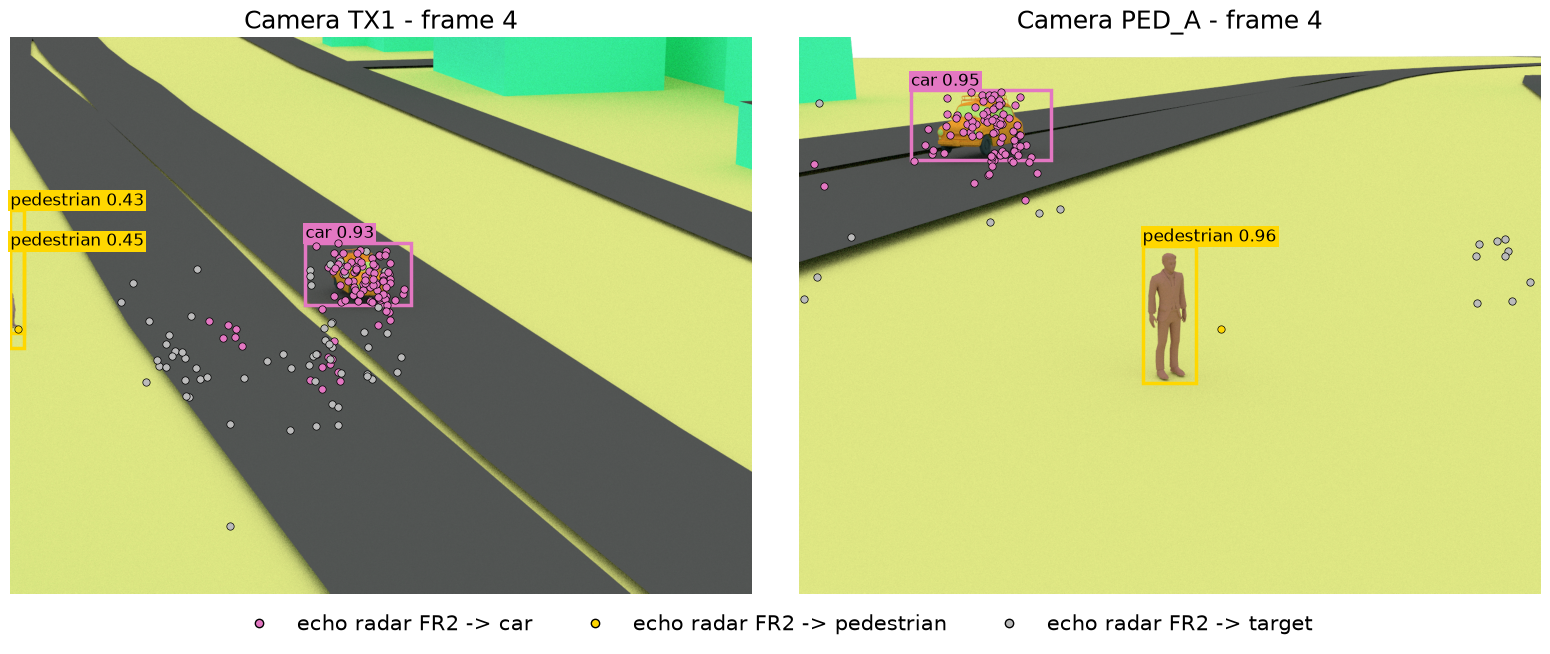

In [16]:
from PIL import Image as PILImage
from matplotlib.patches import Rectangle
from matplotlib.lines import Line2D

T_SHOW, CAM_SHOW = 4, ["tx1", "ped_a"]
CLS_COL = {"car": "#e377c2", "pedestrian": "#ffd700", "target": "#bbbbbb"}
m = MEAS[("FR2", T_SHOW)]
cams = FRAMES[T_SHOW]["cameras"]
mv = ((m["snr_db"] >= SNR_MIN_DB) & (np.abs(m["doppler_hz"]) >= BANDS["FR2"]["doppler_res_hz"])
      & (m["point"][:, 2] < 3.0))
labels = []
for q in m["point"][mv]:
    det, _ = refine(q, cams)
    labels.append(det["cls"] if det is not None else "target")
fig, axes = plt.subplots(1, 2, figsize=(16, 6.4))
for ax, cam in zip(axes, CAM_SHOW):
    img = (PHASE3_DIR / f"module1b_camera_{cam}.png" if T_SHOW == 0
           else PHASE3_DIR / "frames_v2" / f"frame_{T_SHOW:02d}_{cam}.png")
    ax.imshow(PILImage.open(img))
    c = cams[cam]
    for d in c["detections"]:
        x0, y0, x1, y1 = d["bbox_xyxy"]
        ax.add_patch(Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, lw=2.5, ec=CLS_COL.get(d["cls"], "w")))
        ax.text(x0, y0 - 8, f"{d['cls']} {d['conf']:.2f}", color="black", fontsize=12,
                bbox=dict(fc=CLS_COL.get(d["cls"], "w"), ec="none", pad=1.5))
    for q, lab in zip(m["point"][mv], labels):
        uv = project_point(q, c["pos"], c["R"], c["f_px"])
        if uv is not None:
            ax.scatter(*uv, s=28, color=CLS_COL[lab], edgecolor="black", linewidth=0.5, zorder=5)
    ax.set_title(f"Camera {cam.upper()} - frame {T_SHOW}")
    ax.axis("off")
handles = [Line2D([], [], ls="", marker="o", mec="k", color=CLS_COL[k], label=f"echo radar FR2 -> {k}")
           for k in ("car", "pedestrian", "target")]
fig.legend(handles=handles, loc="lower center", ncol=3, frameon=False)
fig.tight_layout(rect=(0, 0.06, 1, 1))
fig.savefig(PHASE5_DIR / "module2_reconnaissance_camera.png", dpi=150, bbox_inches="tight")
plt.show()

### Visualisation des résultats

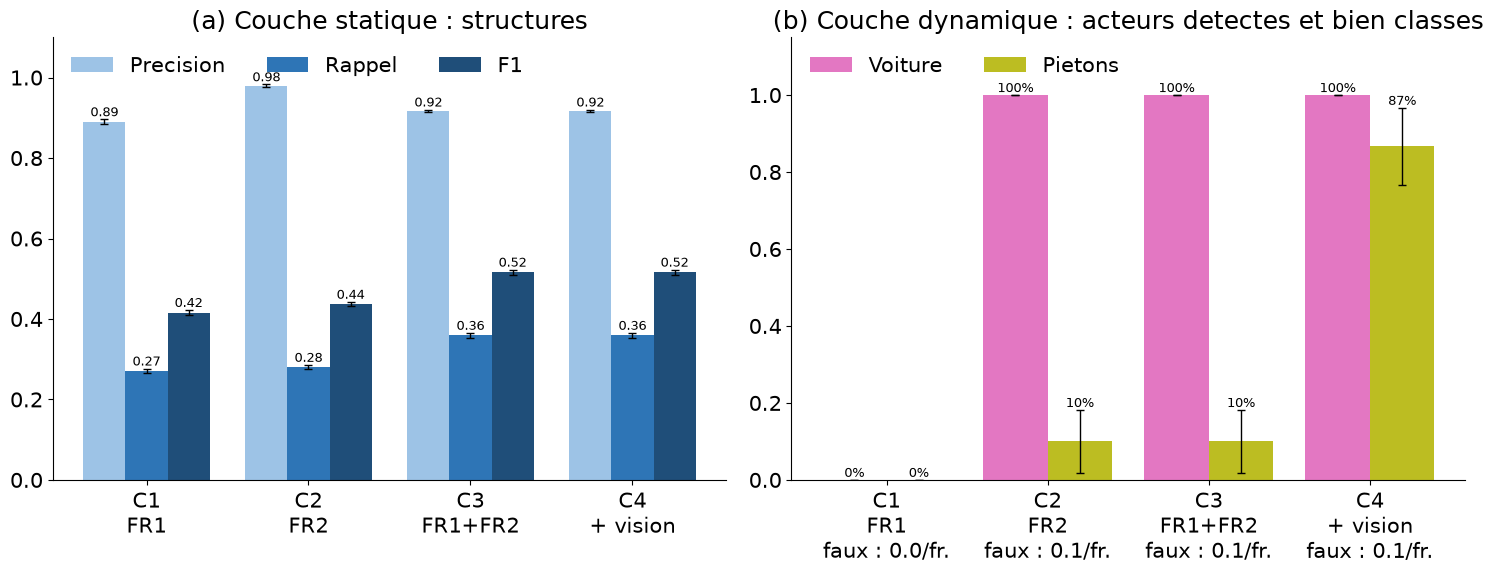

In [17]:
NAMES = list(CONFIGS)
LABELS = ["C1\nFR1", "C2\nFR2", "C3\nFR1+FR2", "C4\n+ vision"]
x = np.arange(len(NAMES))
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for k, (key, lab, col) in enumerate([("structure_precision", "Precision", "#9dc3e6"),
                                      ("structure_rappel", "Rappel", "#2e75b6"),
                                      ("structure_f1", "F1", "#1f4e79")]):
    bars = axes[0].bar(x + (k - 1) * 0.26, [RESULTS[n][key] for n in NAMES], 0.26, label=lab, color=col,
                       yerr=[RESULTS_STD[n][key] for n in NAMES], capsize=3, error_kw={"lw": 1})
    axes[0].bar_label(bars, fmt="%.2f", fontsize=9)
axes[0].set_xticks(x, LABELS)
axes[0].set(ylim=(0, 1.1), title="(a) Couche statique : structures")
axes[0].legend(ncol=3, loc="upper left", frameon=False)
car = [RESULTS[n]["acteurs"]["car"]["classe_correcte"] for n in NAMES]
ped = [(RESULTS[n]["acteurs"]["pedestrian_a"]["classe_correcte"]
        + RESULTS[n]["acteurs"]["pedestrian_b"]["classe_correcte"]) / 2 for n in NAMES]
car_sd = [RESULTS_STD[n]["car_classe"] for n in NAMES]
ped_sd = [(RESULTS_STD[n]["pedestrian_a_classe"] + RESULTS_STD[n]["pedestrian_b_classe"]) / 2 for n in NAMES]
b1 = axes[1].bar(x - 0.2, car, 0.4, label="Voiture", color="#e377c2", yerr=car_sd, capsize=3, error_kw={"lw": 1})
b2 = axes[1].bar(x + 0.2, ped, 0.4, label="Pietons", color="#bcbd22", yerr=ped_sd, capsize=3, error_kw={"lw": 1})
axes[1].bar_label(b1, labels=[f"{v:.0%}" for v in car], fontsize=9)
axes[1].bar_label(b2, labels=[f"{v:.0%}" for v in ped], fontsize=9)
axes[1].set_xticks(x, [f"{l}\nfaux : {RESULTS[n]['faux_objets_par_frame']:.1f}/fr." for l, n in zip(LABELS, NAMES)])
axes[1].set(ylim=(0, 1.15), title="(b) Couche dynamique : acteurs detectes et bien classes")
axes[1].legend(ncol=2, loc="upper left", frameon=False)
fig.tight_layout()
fig.savefig(PHASE5_DIR / "module3_metriques_configurations.png", dpi=180, bbox_inches="tight")
plt.show()

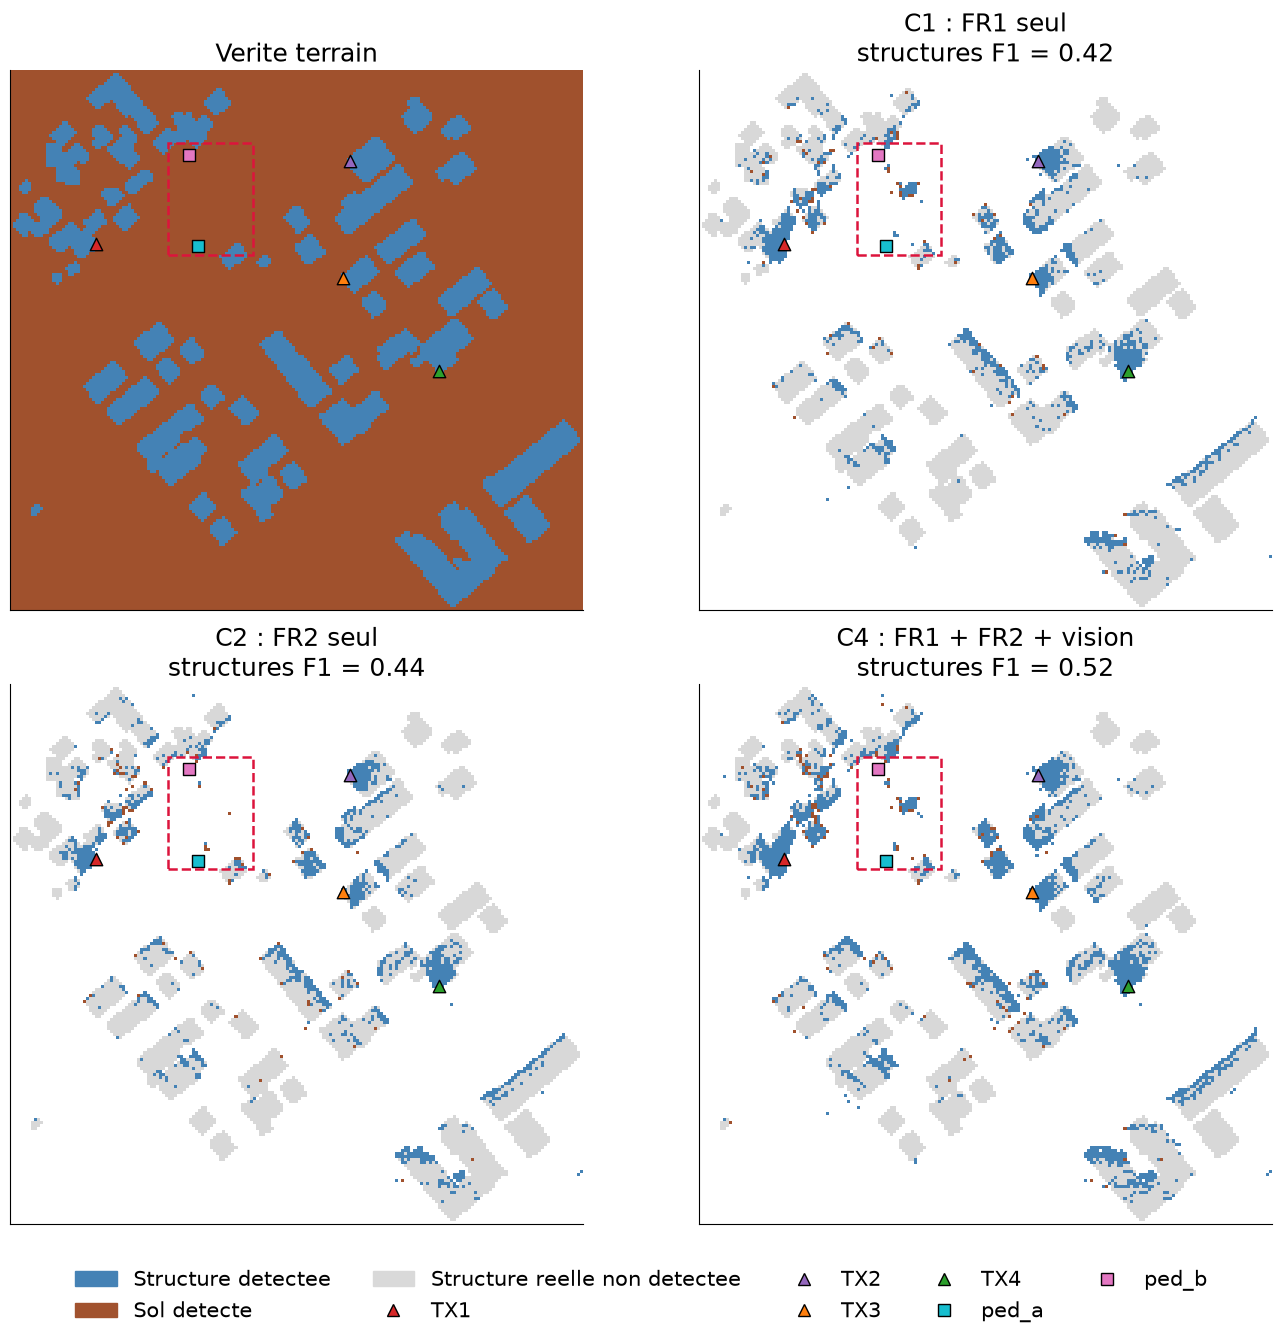

In [18]:
from matplotlib.patches import Rectangle
NODE_COL = {"TX1": "#d62728", "TX2": "#9467bd", "TX3": "#ff7f0e", "TX4": "#2ca02c",
            "ped_a": "#17becf", "ped_b": "#e377c2"}
ZOOM_X, ZOOM_Y = (-72.0, -16.0), (48.0, 122.0)       # zone des acteurs (figure agrandie ci-dessous)


def topdown(ax, struct, ground, title, gt=None):
    img = np.ones((*struct.shape[:2], 3))
    if gt is not None:
        img[gt.any(2)] = (0.85, 0.85, 0.85)
    img[ground.any(2)] = (0.63, 0.32, 0.18)
    img[struct.any(2)] = (0.27, 0.51, 0.71)
    ax.imshow(img.transpose(1, 0, 2), origin="lower", interpolation="nearest",
              extent=[ROI_MIN[0], ROI_MAX[0], ROI_MIN[1], ROI_MAX[1]])
    for n, p in {**BS_POS, **PED_NODE_POS}.items():
        ax.scatter(p[0], p[1], marker="^" if n.startswith("TX") else "s", s=80, color=NODE_COL[n],
                   edgecolor="k", zorder=5)
    ax.add_patch(Rectangle((ZOOM_X[0], ZOOM_Y[0]), ZOOM_X[1] - ZOOM_X[0], ZOOM_Y[1] - ZOOM_Y[0],
                           fill=False, ec="crimson", lw=1.8, ls="--", zorder=6))
    ax.set_title(title)
    ax.set_xticks([]); ax.set_yticks([]); ax.set_aspect("equal")


fig, axes = plt.subplots(2, 2, figsize=(14, 13.5))
axes = axes.ravel()
topdown(axes[0], GT_S, GT_G, "Verite terrain")
for ax, n, lab in zip(axes[1:], ["C1_FR1", "C2_FR2", "C4_FR1+FR2+vision"],
                      ["C1 : FR1 seul", "C2 : FR2 seul", "C4 : FR1 + FR2 + vision"]):
    topdown(ax, TWINS[n]["structure"], TWINS[n]["ground"],
            f"{lab}\nstructures F1 = {RESULTS[n]['structure_f1']:.2f}", gt=GT_S)
from matplotlib.patches import Patch
from matplotlib.lines import Line2D
handles = [Patch(color=(0.27, 0.51, 0.71), label="Structure detectee"),
           Patch(color=(0.63, 0.32, 0.18), label="Sol detecte"),
           Patch(color=(0.85, 0.85, 0.85), label="Structure reelle non detectee")]
handles += [Line2D([], [], ls="", marker="^" if n.startswith("TX") else "s", ms=9, mec="k", color=c, label=n)
            for n, c in NODE_COL.items()]
fig.legend(handles=handles, loc="lower center", ncol=5, frameon=False)
fig.tight_layout(rect=(0, 0.07, 1, 1))
fig.savefig(PHASE5_DIR / "module3_jumeau_vues_dessus.png", dpi=170, bbox_inches="tight")
plt.show()

### Zone des acteurs agrandie : couche dynamique

Cadre pointillé rouge de la figure précédente. Pour chaque configuration : trajectoires réelles des
acteurs sur les 6 frames (lignes), objets retenus par le jumeau (marqueurs pleins, couleur = classe
reconnue) et candidats rejetés par le filtre des fantômes (croix grises). En fond, la couche
statique de la même configuration.

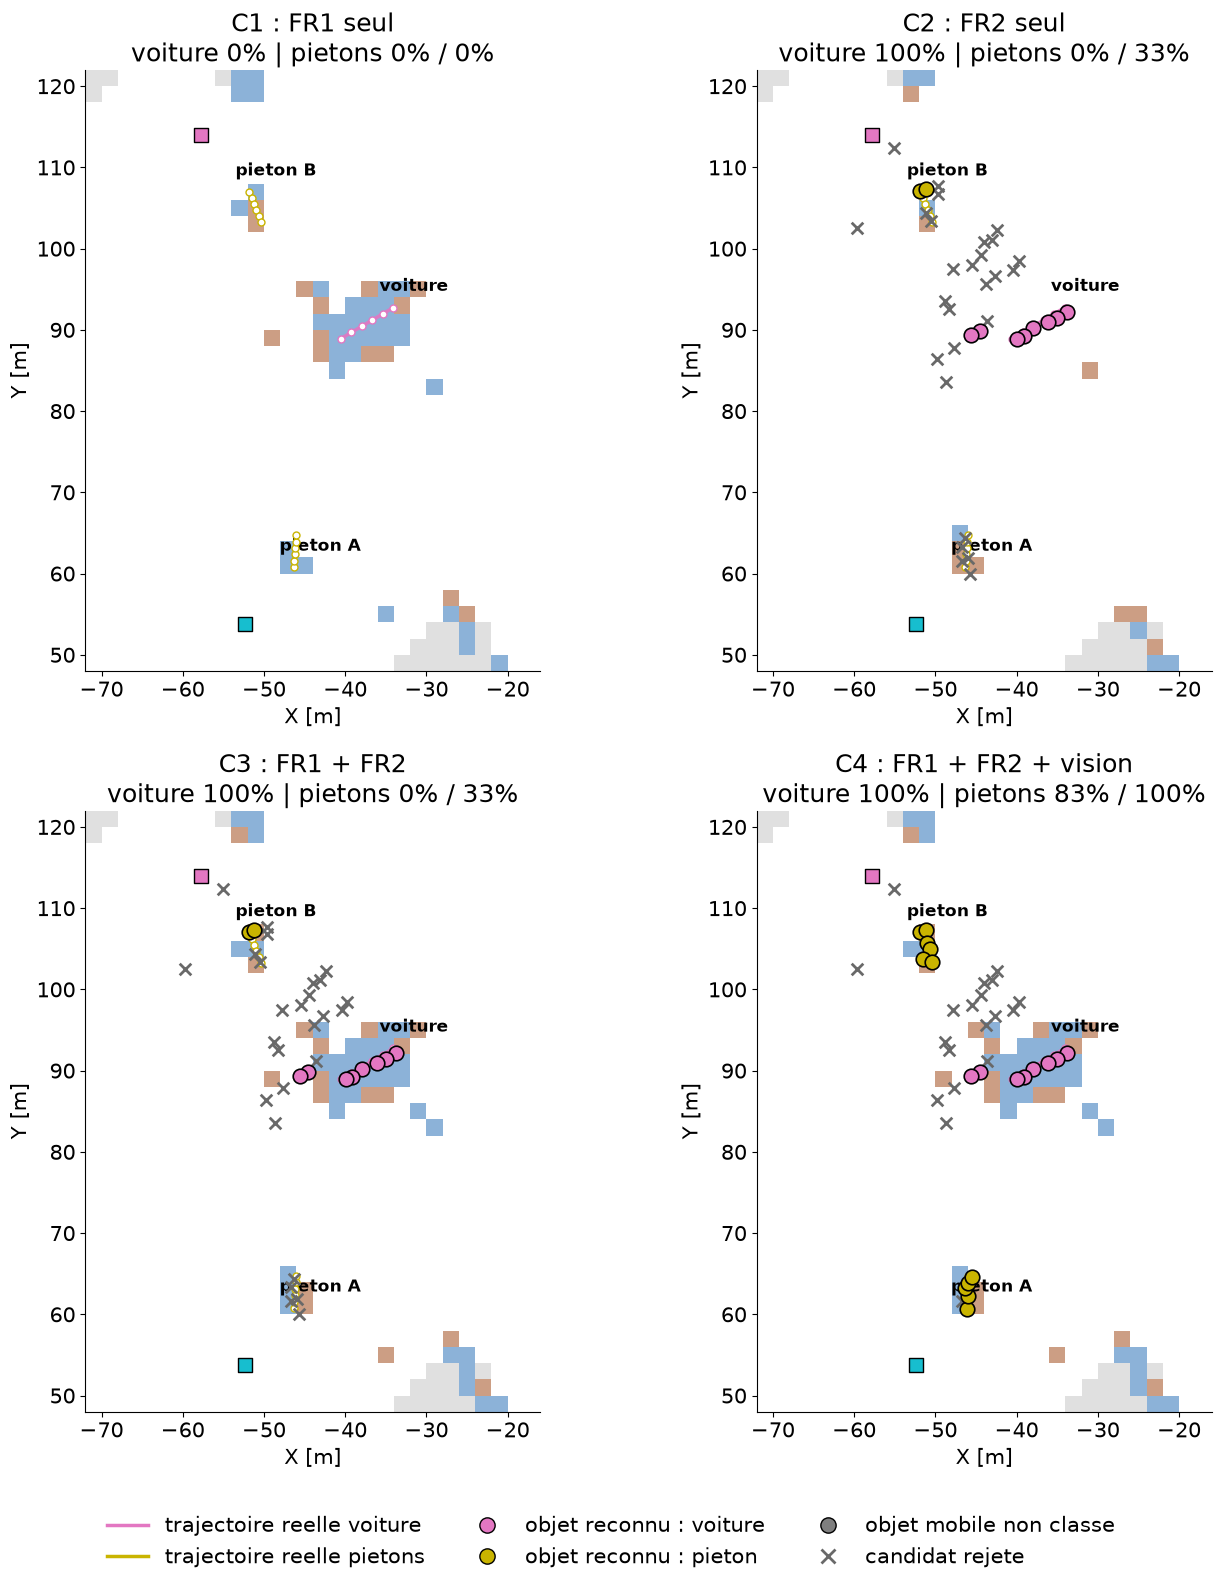

In [19]:
ACT_COL = {"car": "#e377c2", "pedestrian": "#c9b400", "target": "#7f7f7f"}
fig, axes = plt.subplots(2, 2, figsize=(14, 16))
for ax, name, lab in zip(axes.ravel(), CONFIGS,
                         ["C1 : FR1 seul", "C2 : FR2 seul", "C3 : FR1 + FR2", "C4 : FR1 + FR2 + vision"]):
    tw = TWINS[name]
    img = np.ones((*tw["structure"].shape[:2], 3))
    img[GT_S.any(2)] = (0.88, 0.88, 0.88)
    img[tw["ground"].any(2)] = (0.80, 0.62, 0.52)
    img[tw["structure"][:, :, :2].any(2)] = (0.55, 0.70, 0.85)
    ax.imshow(img.transpose(1, 0, 2), origin="lower", interpolation="nearest",
              extent=[ROI_MIN[0], ROI_MAX[0], ROI_MIN[1], ROI_MAX[1]])
    for g in ACTOR_MATERIALS:
        tr = np.array([FRAMES[t]["actors"][g][:2] for t in range(N_FRAMES)])
        ax.plot(tr[:, 0], tr[:, 1], "-", lw=2.5, color=ACT_COL[CLASS_OF_ACTOR[g]], alpha=0.9, zorder=3)
        ax.scatter(tr[:, 0], tr[:, 1], s=25, color="white", edgecolor=ACT_COL[CLASS_OF_ACTOR[g]], zorder=4)
        ax.annotate({"car": "voiture", "pedestrian_a": "pieton A", "pedestrian_b": "pieton B"}[g],
                    tr[0], xytext=(-10, 12), textcoords="offset points", fontsize=12, fontweight="bold")
    for t in range(N_FRAMES):
        for o in tw["rejected"][t]:
            ax.scatter(*o["xy"], marker="x", s=70, color="dimgray", lw=2, zorder=5)
        for o in tw["dynamic"][t]:
            ax.scatter(*o["xy"], marker="o", s=110, color=ACT_COL.get(o["cls"], "gray"),
                       edgecolor="black", lw=1.2, zorder=6)
    for n, p in PED_NODE_POS.items():
        ax.scatter(p[0], p[1], marker="s", s=90, color=NODE_COL[n], edgecolor="k", zorder=7)
    r = REF_RESULTS[name]["acteurs"]
    ax.set_title(f"{lab}\nvoiture {r['car']['classe_correcte']:.0%} | pietons "
                 f"{r['pedestrian_a']['classe_correcte']:.0%} / {r['pedestrian_b']['classe_correcte']:.0%}")
    ax.set_xlim(*ZOOM_X); ax.set_ylim(*ZOOM_Y); ax.set_aspect("equal")
    ax.set_xlabel("X [m]"); ax.set_ylabel("Y [m]")
handles = [Line2D([], [], color=ACT_COL["car"], lw=2.5, label="trajectoire reelle voiture"),
           Line2D([], [], color=ACT_COL["pedestrian"], lw=2.5, label="trajectoire reelle pietons"),
           Line2D([], [], ls="", marker="o", ms=11, mec="k", color=ACT_COL["car"], label="objet reconnu : voiture"),
           Line2D([], [], ls="", marker="o", ms=11, mec="k", color=ACT_COL["pedestrian"], label="objet reconnu : pieton"),
           Line2D([], [], ls="", marker="o", ms=11, mec="k", color=ACT_COL["target"], label="objet mobile non classe"),
           Line2D([], [], ls="", marker="x", ms=10, mew=2, color="dimgray", label="candidat rejete")]
fig.legend(handles=handles, loc="lower center", ncol=3, frameon=False)
fig.tight_layout(rect=(0, 0.06, 1, 1))
fig.savefig(PHASE5_DIR / "module3_couche_dynamique_zoom.png", dpi=160, bbox_inches="tight")
plt.show()

### Vue 3D interactive du jumeau (C4)

Structures et sol (voxels de 2 m), acteurs détectés sur les 6 frames, noeuds de sensing.
Rotation, zoom et survol directement dans la cellule.

In [20]:
import plotly.graph_objects as go

tw = TWINS["C4_FR1+FR2+vision"]
cs = ROI_MIN + (np.argwhere(tw["structure"]) + 0.5) * VOXEL
cg = ROI_MIN + (np.argwhere(tw["ground"]) + 0.5) * VOXEL
fig = go.Figure()
fig.add_trace(go.Scatter3d(x=cs[:, 0], y=cs[:, 1], z=cs[:, 2], mode="markers", name="Structures",
                           marker=dict(size=2, color=cs[:, 2], colorscale="Blues", cmin=-8, cmax=26)))
fig.add_trace(go.Scatter3d(x=cg[:, 0], y=cg[:, 1], z=cg[:, 2], mode="markers", name="Sol",
                           marker=dict(size=2, color="sienna")))
for cls, col in [("car", "#e377c2"), ("pedestrian", "#bcbd22")]:
    pts = [(o["xy"][0], o["xy"][1], t) for t, fr in enumerate(tw["dynamic"]) for o in fr if o["cls"] == cls]
    if pts:
        p = np.array(pts)
        fig.add_trace(go.Scatter3d(x=p[:, 0], y=p[:, 1], z=np.ones(len(p)), mode="markers", name=cls,
                                   text=[f"frame {int(v)}" for v in p[:, 2]],
                                   marker=dict(size=6, color=col, line=dict(width=1, color="black"))))
nodes = {**BS_POS, **PED_NODE_POS}
nxyz = np.array(list(nodes.values()))
fig.add_trace(go.Scatter3d(x=nxyz[:, 0], y=nxyz[:, 1], z=nxyz[:, 2], mode="markers+text",
                           text=list(nodes), name="Noeuds", marker=dict(size=7, symbol="diamond", color="crimson")))
fig.update_layout(height=700, margin=dict(l=0, r=0, t=30, b=0), title="Jumeau numerique - C4",
                  scene=dict(aspectmode="manual", aspectratio=dict(x=1.1, y=1, z=0.3)))
fig.show()

## 9. Résumé et validation Phase 5

In [21]:
best = RESULTS["C4_FR1+FR2+vision"]
fr1_err = float(np.median(np.linalg.norm(MEAS[("FR1", 0)]["point"] - MEAS[("FR1", 0)]["last_vertex"], axis=1)[(MEAS[("FR1", 0)]["snr_db"] >= SNR_MIN_DB) & (MEAS[("FR1", 0)]["depth"] == 1)]))
fr2_err = float(np.median(np.linalg.norm(MEAS[("FR2", 0)]["point"] - MEAS[("FR2", 0)]["last_vertex"], axis=1)[(MEAS[("FR2", 0)]["snr_db"] >= SNR_MIN_DB) & (MEAS[("FR2", 0)]["depth"] == 1)]))
clean_err = max(float(np.median(np.linalg.norm(MEAS[(b, 0)]["point_clean"] - MEAS[(b, 0)]["last_vertex"], axis=1)[MEAS[(b, 0)]["depth"] == 1])) for b in BANDS)
ped = lambda n: (RESULTS[n]["acteurs"]["pedestrian_a"]["classe_correcte"] + RESULTS[n]["acteurs"]["pedestrian_b"]["classe_correcte"]) / 2

summary = {
    "project": "SDM-VA-ISAC", "phase": 5, "scene_xml": str(SCENE_XML),
    "bands": {b: {k: float(v) for k, v in p.items()} for b, p in BANDS.items()},
    "cpi_s": CPI_S, "snr_min_db": SNR_MIN_DB, "voxel_m": VOXEL, "n_frames": N_FRAMES,
    "median_point_error_m": {"FR1": fr1_err, "FR2": fr2_err},
    "n_tirages_bruit": N_TRIALS,
    "configurations": RESULTS, "configurations_ecart_type": RESULTS_STD,
    "configurations_tirage_reference": REF_RESULTS,
    "validation": {
        "radar_reconstruction_exact_without_noise": clean_err < 0.05,
        "fr2_more_accurate_than_fr1": fr2_err < fr1_err,
        "fr2_separates_movers_by_doppler": RESULTS["C2_FR2"]["acteurs"]["car"]["classe_correcte"] > 0,
        "dual_band_improves_structure_f1": RESULTS["C3_FR1+FR2"]["structure_f1"] > max(RESULTS["C1_FR1"]["structure_f1"], RESULTS["C2_FR2"]["structure_f1"]),
        "vision_objects_improve_pedestrians": ped("C4_FR1+FR2+vision") > ped("C3_FR1+FR2"),
        "rare_false_objects_final_config": best["faux_objets_par_frame"] < 0.5,
    },
}
with open(PHASE5_DIR / "phase5_summary.json", "w", encoding="utf-8") as f:
    json.dump(summary, f, indent=2, ensure_ascii=False)
print(f"Resume Phase 5 sauvegarde -> {PHASE5_DIR / 'phase5_summary.json'}\n")
print("=== VALIDATION PHASE 5 ===")
for k, ok in summary["validation"].items():
    print(f"  {'OK' if ok else 'X '}  {k}")

Resume Phase 5 sauvegarde -> C:\Users\AdminFix\Desktop\PFA\phase5\phase5_summary.json

=== VALIDATION PHASE 5 ===
  OK  radar_reconstruction_exact_without_noise
  OK  fr2_more_accurate_than_fr1
  OK  fr2_separates_movers_by_doppler
  OK  dual_band_improves_structure_f1
  OK  vision_objects_improve_pedestrians
  OK  rare_false_objects_final_config


## 10. Conclusions

- **Les deux bandes sont complémentaires.** FR2 localise mieux (0,44 m contre 0,77 m, deux fois
  moins de points hors surface) grâce à une meilleure résolution angulaire, et il est seul à
  séparer les cibles lentes par le Doppler. FR1 apporte des échos supplémentaires : ensemble, les
  deux bandes augmentent de 30 % le rappel des structures (F1 0,52 contre 0,42–0,44).
- **La vision compense ce que le radar ne voit pas.** Les objets créés par la vision portent la
  reconnaissance des piétons de 0–20 % à 77–97 %, la voiture restant reconnue à 100 %.
- **Le filtre des fantômes repose sur la géométrie** : deux récepteurs distincts. Il élimine
  presque tous les fantômes (0,08 faux objet par frame), au prix des cibles faibles vues d'un seul
  point de vue, que la vision récupère.
- **Le diagnostic a amélioré la fusion** : distance relative et contrôle de profondeur corrigent
  une confusion piéton / voiture héritée de la phase 3.

**Limites.**
- Rappel du sol faible et rappel des structures plafonné par la géométrie des noeuds en toiture ;
  des noeuds plus proches du sol ou mieux répartis seraient nécessaires.
- Les échos FR1 des acteurs, non reconnus comme mobiles, laissent quelques fausses structures.
- Les paramètres du bilan de liaison (CPI, puissances, réseaux) sont des hypothèses réalistes,
  sans étude de sensibilité.
- La géométrie des trajets varie très légèrement d'une exécution à l'autre (échantillonnage des
  réflexions diffuses sur GPU) ; les moyennes sur 10 tirages du bruit rendent les conclusions
  robustes, mais les valeurs peuvent différer à la marge d'une exécution à l'autre.